# Population has a date and a boundary

**Objective:** Distinguish full-tract counts from a study-area estimate and examine a population distribution without assigning individuals to pixels.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

POP100 is the 2020 Census total population for the **whole tract**. A tract that touches our box may extend far beyond it. Adding all intersecting tracts therefore does not count people within the box. The portal separately offers a polygon-area estimate with a strong assumption: people are distributed uniformly within each tract, including nonresidential land. This assumption can be badly wrong.

Population in 2020 is not a measured population at the Landsat overpass in 2024. Counts do not reveal vulnerability, daily movement or who was exposed.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=02_population.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
counts = [int(f["properties"]["POP100"]) for f in tracts]
assert len(counts) == 166 and sum(counts) == 764468
print("People in the 166 WHOLE intersecting tracts:", sum(counts))
print("This is NOT bbox population.")
print("Median whole-tract population:", statistics.median(counts))

People in the 166 WHOLE intersecting tracts: 764468
This is NOT bbox population.
Median whole-tract population: 4611.5


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

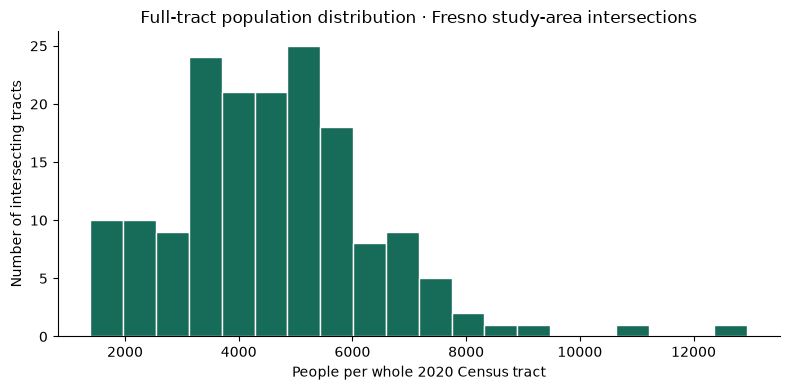

In [3]:
plt.hist(counts, bins=20, color="#176c59", edgecolor="white")
plt.xlabel("People per whole 2020 Census tract"); plt.ylabel("Number of intersecting tracts")
plt.title("Full-tract population distribution · Fresno study-area intersections")
plt.tight_layout(); plt.show()

## Interpret and extend

Compare an agricultural tract and a dense residential tract in the explorer. Explain how area weighting could misallocate people. Which public-domain source might improve the spatial allocation, and what rights and vintage checks would be necessary?

## Sources and attribution

- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.